# SupportIQ: 2025 complaint analysis

Questions for this notebook:

- How does complaint volume change through the year?
- Which products and companies account for the most complaints?
- How much narrative text is available, and how much repeats?
- What response categories and timely-response patterns are recorded?
- Does the model sample preserve the product mix of the model pool?

Business counts use **all source rows**, including repeated narratives and complaints without narratives. Model splits use deduplicated text. Counts describe this archived CFPB dataset, not the whole financial services market. No complaint text is printed here.

**Dataset version note:** The model-sample balance section below describes the original 30,000-row sample. Current model comparisons must use `data/processed-2025-v2`; see `reports/split_audit` for near-duplicate removal, merged labels, and revised counts. Business charts still include all analytics rows.

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Markdown, display

assert sys.version_info[:2] == (3, 11), "Select the project's Python 3.11 environment"
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
folder = root / "data" / "analytics-2025"
model_folder = root / "data" / "processed-2025"
out = root / "reports" / "eda"
out.mkdir(parents=True, exist_ok=True)
manifest = json.loads((folder / "manifest.json").read_text())
model = json.loads((model_folder / "manifest.json").read_text())
assert manifest["rows"] == model["input_rows"]
assert {(s["file"], s["sha256"]) for s in manifest["sources"]} == {(s["file"], s["sha256"]) for s in model["sources"]}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"Python {sys.version.split()[0]}; pandas {pd.__version__}")

Python 3.11.15; pandas 3.0.6


## Count metadata in batches

Parquet lets us read selected columns without loading narratives. Each batch contributes small count tables. `is_duplicate_text` flags later occurrences of the same normalized narrative; the first occurrence is unflagged. This is a text flag, not a determination that two complaints concern the same event.

In [2]:
months, products, companies, responses = Counter(), Counter(), Counter(), Counter()
company_products, timely_yes, timely_no = Counter(), Counter(), Counter()
pool_products = Counter()
n_rows = n_text = n_repeated = 0
n_yes = n_no = 0
columns = ["date_received", "topic", "company", "company_response", "timely_response", "has_narrative", "is_duplicate_text"]
for source in manifest["sources"]:
    file = pq.ParquetFile(folder / source["output"])
    assert file.metadata.num_rows == source["rows"]
    for batch in file.iter_batches(batch_size=50000, columns=columns):
        df = batch.to_pandas()
        df["company"] = df["company"].fillna("").replace("", "Unknown")
        df["topic"] = df["topic"].fillna("").replace("", "Unknown")
        months.update(df["date_received"].str[:7].value_counts().to_dict())
        products.update(df["topic"].value_counts().to_dict())
        companies.update(df["company"].value_counts().to_dict())
        responses.update(df["company_response"].fillna("").replace("", "Unknown").value_counts().to_dict())
        company_products.update(df.groupby(["company", "topic"]).size().to_dict())
        timely = df["timely_response"].fillna("").str.strip().str.casefold()
        timely_yes.update(df.loc[timely.eq("yes"), "company"].value_counts().to_dict())
        timely_no.update(df.loc[timely.eq("no"), "company"].value_counts().to_dict())
        pool = df["has_narrative"] & ~df["is_duplicate_text"]
        pool_products.update(df.loc[pool, "topic"].value_counts().to_dict())
        n_rows += len(df)
        n_text += int(df["has_narrative"].sum())
        n_repeated += int(df["is_duplicate_text"].sum())
        n_yes += int(timely.eq("yes").sum())
        n_no += int(timely.eq("no").sum())

assert n_rows == manifest["rows"] == sum(months.values()) == sum(products.values())
assert n_text == manifest["with_narrative"]
assert n_repeated == manifest["duplicate_text"]
assert n_text - n_repeated == model["clean_rows"]
assert set(months) == {f"2025-{m:02d}" for m in range(1, 13)}

summary = pd.DataFrame({"population": ["All complaints", "With narrative", "Repeated narrative (later copies)", "Model pool", "Model sample"],
                        "rows": [n_rows, n_text, n_repeated, model["clean_rows"], model["sample_size"]]})
summary["share_of_all_pct"] = summary["rows"] / n_rows * 100
summary.to_csv(out / "population.csv", index=False)
display(summary.round(2))

,population,rows,share_of_all_pct
0,All complaints,5442964,100.00
1,With narrative,1222050,22.45
2,Repeated narrative (later copies),614119,11.28
3,Model pool,607931,11.17
4,Model sample,30000,0.55


The population rows above overlap: repeated narratives are a subset of complaints with narratives, and the model sample is a subset of the model pool. Do not add them together. The equality between unique narratives and the model pool is checked for this export; it could fail on a different dataset with missing IDs, missing products, or invalid dates.

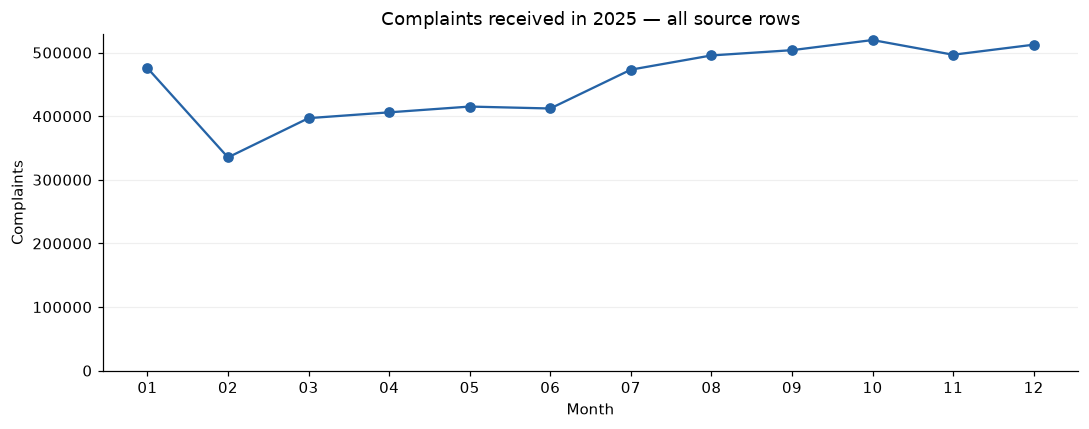

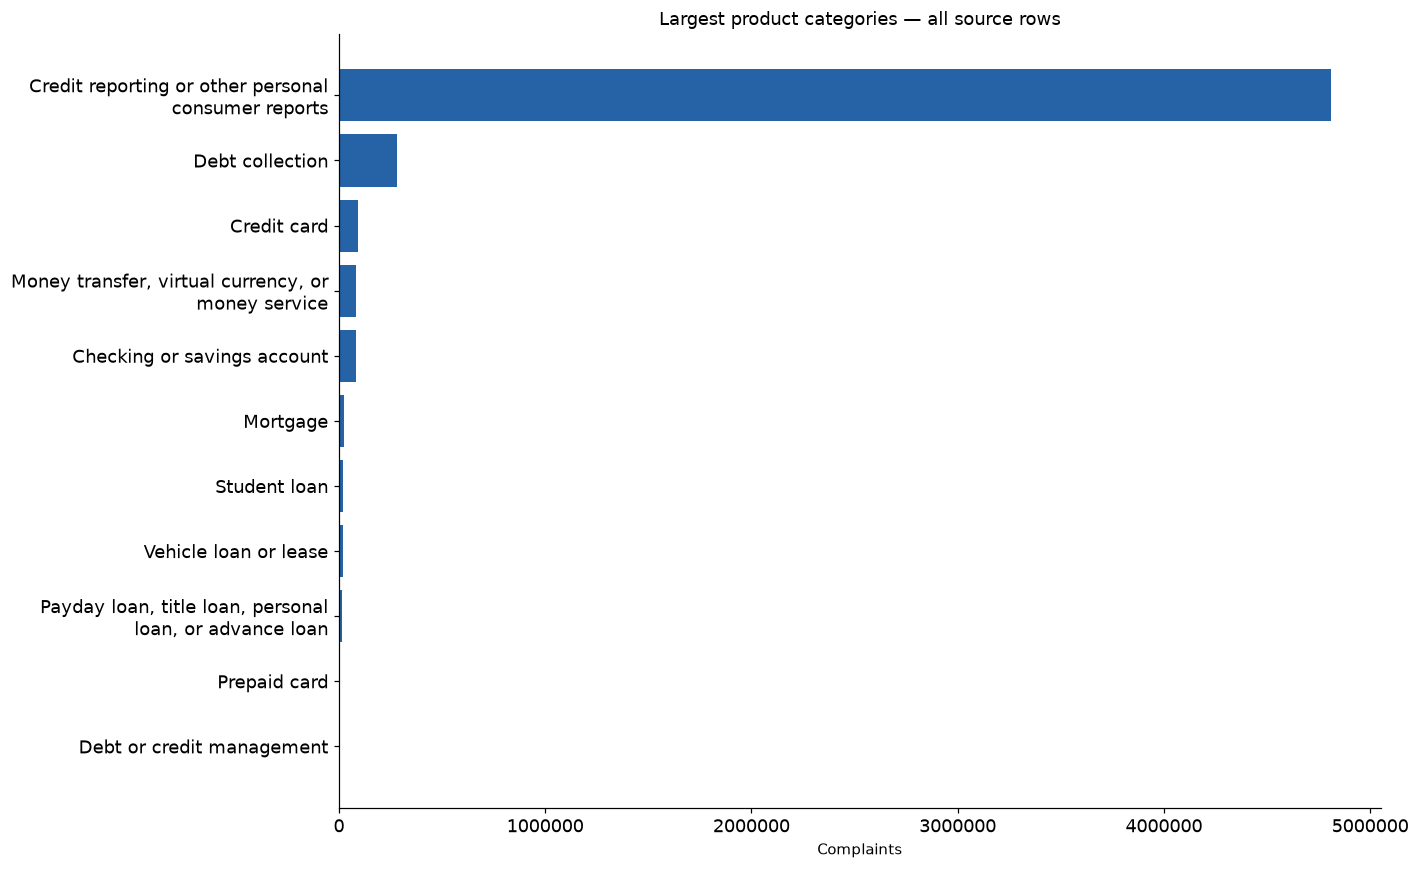

,topic,complaints,share_pct
0,Credit reporting or other personal consumer re...,4810302,88.38
1,Debt collection,283204,5.20
2,Credit card,89978,1.65
3,"Money transfer, virtual currency, or money ser...",84619,1.55
4,Checking or savings account,84195,1.55
5,Mortgage,24697,0.45
6,Student loan,21295,0.39
7,Vehicle loan or lease,20769,0.38
8,"Payday loan, title loan, personal loan, or adv...",13137,0.24
9,Prepaid card,6502,0.12


In [3]:
monthly = pd.Series(months, name="complaints").sort_index().rename_axis("month").reset_index()
topics = pd.Series(products, name="complaints").sort_values(ascending=False).rename_axis("topic").reset_index()
topics["share_pct"] = topics["complaints"] / n_rows * 100
monthly.to_csv(out / "monthly.csv", index=False)
topics.to_csv(out / "products.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly["month"].str[-2:], monthly["complaints"], marker="o", color="#2563a6")
ax.set(title="Complaints received in 2025 — all source rows", xlabel="Month", ylabel="Complaints")
ax.ticklabel_format(axis="y", style="plain")
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(out / "monthly.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(13, 8))
shown = topics.head(12).iloc[::-1]
ax.barh([fill(t, 38) for t in shown["topic"]], shown["complaints"], color="#2563a6")
ax.set(title="Largest product categories — all source rows", xlabel="Complaints")
ax.ticklabel_format(axis="x", style="plain")
ax.tick_params(axis="both", labelsize=12)
fig.tight_layout()
fig.savefig(out / "products.png", bbox_inches="tight")
plt.show()
display(topics.round(2))

## Company patterns and recorded responses

High complaint counts can reflect a large customer base, market coverage, repeated submissions, or other factors. They are not a ranking of company quality. Timely response is measured among records explicitly marked Yes or No; unknown responses are shown separately. Response categories are not a verified resolution rate.

,company,complaints,timely_yes,timely_no,timely_known,timely_unknown,timely_pct_known,largest_product
0,"EQUIFAX, INC.",1680536,1680536,0,1680536,0,100.00,Credit reporting or other personal consumer re...
1,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",1601849,1601849,0,1601849,0,100.00,Credit reporting or other personal consumer re...
2,Experian Information Solutions Inc.,1388821,1388789,32,1388821,0,100.00,Credit reporting or other personal consumer re...
3,"Block, Inc.",48091,47241,850,48091,0,98.23,"Money transfer, virtual currency, or money ser..."
4,CAPITAL ONE FINANCIAL CORPORATION,34102,34100,2,34102,0,99.99,Credit reporting or other personal consumer re...
5,"CBC Companies, Inc.",30769,30769,0,30769,0,100.00,Credit reporting or other personal consumer re...
6,"Early Warning Services, LLC",24509,24507,2,24509,0,99.99,"Money transfer, virtual currency, or money ser..."
7,JPMORGAN CHASE & CO.,24458,24458,0,24458,0,100.00,Checking or savings account
8,Resurgent Capital Services L.P.,23741,23740,1,23741,0,100.00,Debt collection
9,"CITIBANK, N.A.",19792,19791,1,19792,0,99.99,Credit card


,response,complaints,share_pct
0,Closed with explanation,3194726,58.69
1,Closed with non-monetary relief,2212234,40.64
2,Closed with monetary relief,26125,0.48
3,Untimely response,9594,0.18
4,In progress,285,0.01


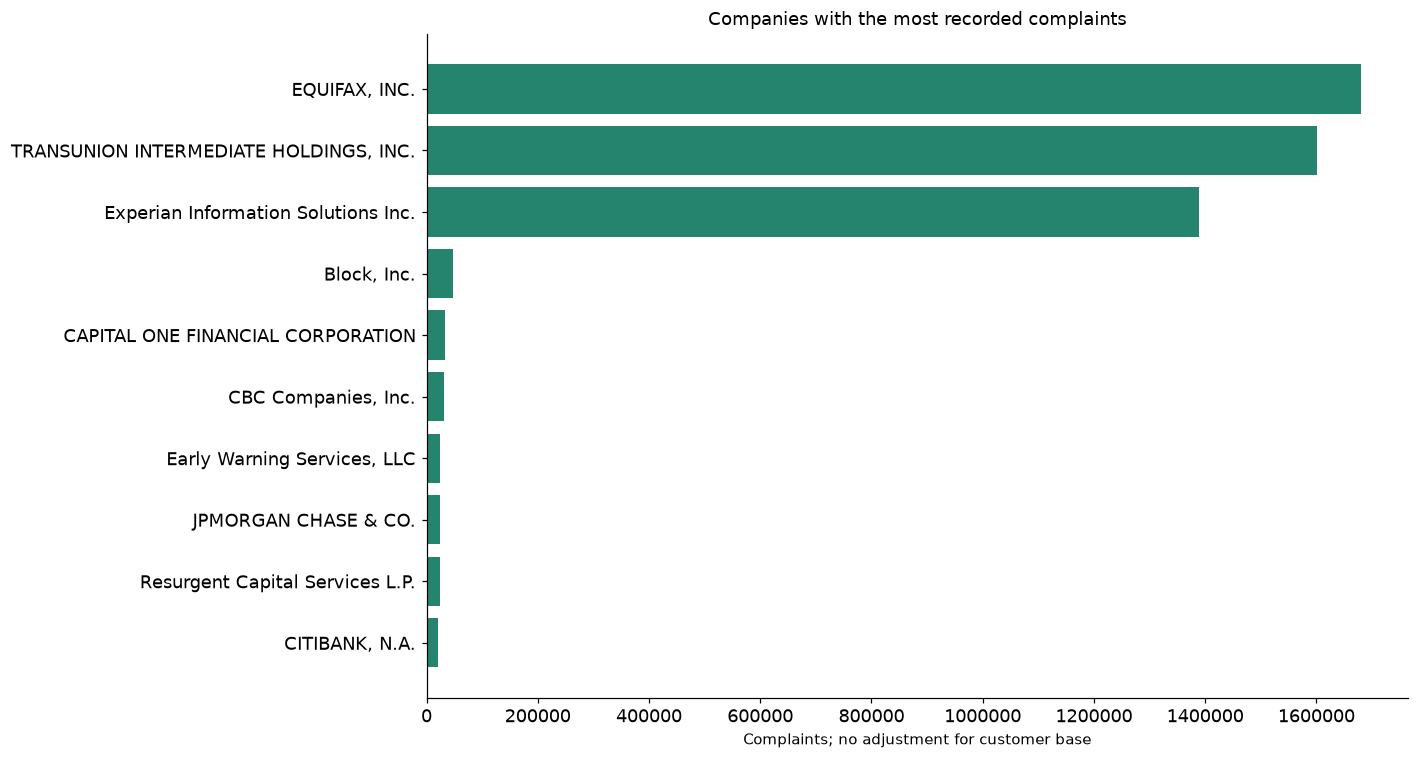

In [4]:
company = pd.Series(companies, name="complaints").rename_axis("company").reset_index()
company["timely_yes"] = company["company"].map(timely_yes).fillna(0).astype(int)
company["timely_no"] = company["company"].map(timely_no).fillna(0).astype(int)
company["timely_known"] = company["timely_yes"] + company["timely_no"]
company["timely_unknown"] = company["complaints"] - company["timely_known"]
company["timely_pct_known"] = company["timely_yes"] / company["timely_known"].replace(0, float("nan")) * 100
pairs = pd.Series(company_products, name="complaints").rename_axis(["company", "topic"]).reset_index()
leaders = pairs.sort_values(["complaints", "topic"], ascending=[False, True]).drop_duplicates("company").set_index("company")["topic"]
company["largest_product"] = company["company"].map(leaders)
company = company.sort_values(["complaints", "company"], ascending=[False, True]).reset_index(drop=True)
company.to_csv(out / "companies.csv", index=False)
pairs.to_csv(out / "company_products.csv", index=False)
response = pd.Series(responses, name="complaints").sort_values(ascending=False).rename_axis("response").reset_index()
response["share_pct"] = response["complaints"] / n_rows * 100
response.to_csv(out / "responses.csv", index=False)
assert company["complaints"].sum() == response["complaints"].sum() == n_rows
assert company["timely_known"].sum() == n_yes + n_no

display(company.head(10).round(2))
display(response.round(2))
fig, ax = plt.subplots(figsize=(13, 7))
shown = company.head(10).iloc[::-1]
ax.barh([fill(name, 38) for name in shown["company"]], shown["complaints"], color="#25846d")
ax.set(title="Companies with the most recorded complaints", xlabel="Complaints; no adjustment for customer base")
ax.ticklabel_format(axis="x", style="plain")
ax.tick_params(axis="both", labelsize=12)
fig.tight_layout()
fig.savefig(out / "companies.png", bbox_inches="tight")
plt.show()

## Model sample balance

This compares the model sample with the deduplicated model pool, not with all business complaints. Rare products use the same minimum-count rule as data preparation. These are label-count checks, not model scores. Test narratives are not inspected or used for model selection.

,pool_rows,sample_rows,pool_pct,sample_pct,difference_pp
Checking or savings account,47095,2324,7.7468,7.7467,-0.0001
Credit card,39161,1932,6.4417,6.4400,-0.0017
Credit reporting or other personal consumer reports,356705,17603,58.6752,58.6767,0.0014
Debt collection,75192,3710,12.3685,12.3667,-0.0018
Debt or credit management,2566,127,0.4221,0.4233,0.0012
"Money transfer, virtual currency, or money service",39279,1938,6.4611,6.4600,-0.0011
Mortgage,14023,692,2.3067,2.3067,-0.0000
"Payday loan, title loan, personal loan, or advance loan",7774,384,1.2788,1.2800,0.0012
Prepaid card,3818,188,0.6280,0.6267,-0.0014
Student loan,10692,528,1.7588,1.7600,0.0012


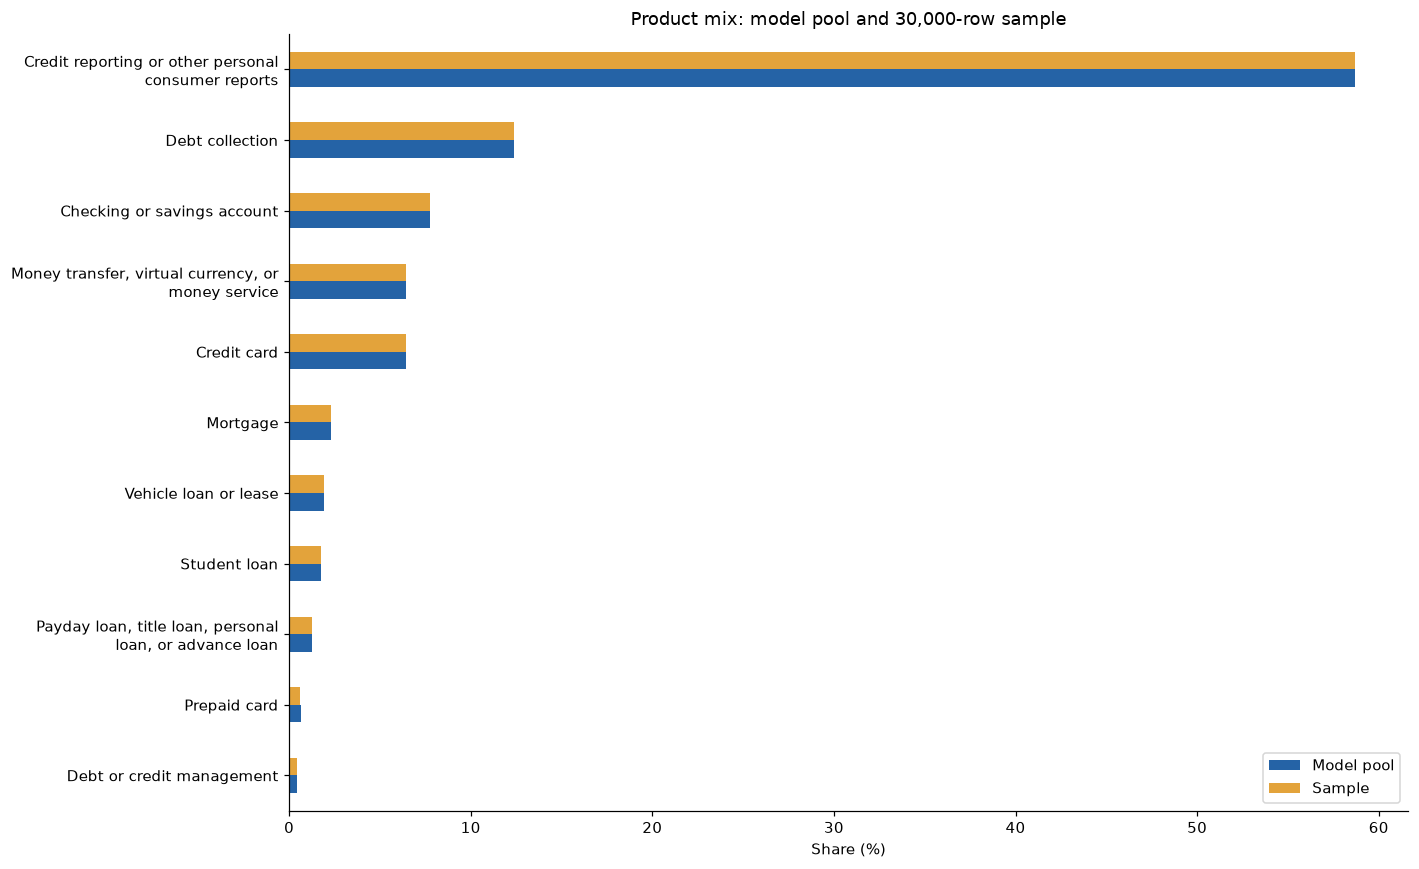

In [5]:
pool_counts = pd.Series(pool_products, name="pool_rows")
pool_counts.index = pool_counts.index.where(pool_counts >= model["min_class"], "Other")
pool_counts = pool_counts.groupby(level=0).sum()
sample_counts = Counter()
for name in ("train", "val", "test"):
    counts = pd.read_csv(model_folder / f"{name}.csv", usecols=["topic"])["topic"].value_counts()
    assert counts.to_dict() == model["splits"][name]["topics"]
    sample_counts.update(counts.to_dict())
balance = pd.concat([pool_counts, pd.Series(sample_counts, name="sample_rows")], axis=1).fillna(0)
balance["pool_pct"] = balance["pool_rows"] / balance["pool_rows"].sum() * 100
balance["sample_pct"] = balance["sample_rows"] / balance["sample_rows"].sum() * 100
balance["difference_pp"] = balance["sample_pct"] - balance["pool_pct"]
assert balance["sample_rows"].sum() == model["sample_size"]
assert balance["difference_pp"].abs().max() <= 100 / model["sample_size"] + 1e-9
balance.rename_axis("topic").to_csv(out / "sample_balance.csv")
display(balance.round(4))

fig, ax = plt.subplots(figsize=(13, 8))
balance.sort_values("pool_pct")[["pool_pct", "sample_pct"]].rename(index=lambda name: fill(name, 38)).plot.barh(ax=ax, color=["#2563a6", "#e3a33b"])
ax.set(title="Product mix: model pool and 30,000-row sample", xlabel="Share (%)", ylabel="")
ax.legend(["Model pool", "Sample"])
fig.tight_layout()
fig.savefig(out / "sample_balance.png", bbox_inches="tight")
plt.show()

## Findings and follow-up questions

The report below is built from the counts above. It separates measured observations from possible follow-up work. It does not infer causes from volume alone.

In [6]:
peak = monthly.loc[monthly["complaints"].idxmax()]
first = topics.iloc[0]
known = n_yes + n_no
rate = f"{n_yes / known:.2%}" if known else "not available"
report = f"""# 2025 complaint insights

Source: the six official CFPB 2025 archive exports. Analytics keeps all source rows, including repeated narratives and complaints without narratives. This is an archived snapshot, not a market-wide incidence study.

## Measured observations

- The files contain **{n_rows:,} complaints** across all twelve months of 2025.
- **{n_text:,} ({n_text / n_rows:.2%})** contain a narrative. **{n_rows - n_text:,}** do not.
- **{n_repeated:,} ({n_repeated / n_text:.2%} of narrative-bearing rows)** are later copies of normalized text already encountered. These remain in business counts.
- The largest recorded product category is **{first['topic']}**, with **{int(first['complaints']):,} complaints ({first['share_pct']:.2f}%)**.
- The highest monthly volume is **{peak['month']}**, with **{int(peak['complaints']):,} complaints**.
- The company with the most recorded complaints is **{company.iloc[0]['company']}**, with **{int(company.iloc[0]['complaints']):,}**. This does not establish a higher failure rate.
- **{n_yes:,}** records indicate a timely response and **{n_no:,}** indicate a late response. The timely share is **{rate} among {known:,} known responses**; **{n_rows - known:,}** records have an unknown or other value.
- The model pool contains **{model['clean_rows']:,} unique normalized narratives**. The 30,000-row sample differs from its product proportions by at most **{balance['difference_pp'].abs().max():.4f} percentage points**.

## What to investigate next

- Review sub-issues within the largest product category before proposing operational changes. Product counts alone do not identify causes.
- Compare monthly company/product counts and source revisions before interpreting the peak month as a business event.
- Inspect repeated-text patterns separately; repeated wording can represent distinct customers and should not automatically be treated as invalid.
- Obtain customer-base denominators before comparing company complaint rates.

## Limits

Response categories and timely responses are not a verified resolution rate. This dataset does not yet contain sentiment or urgency predictions, so neither metric is reported. Narrative availability and deduplication change the population used by the future classifier. Random model splits do not measure future-period performance.

## Reproduce

Run `python notebooks/run_eda.py` after preparing both the analytics files and model splits. The notebook checks source hashes in the manifests, row totals, twelve-month coverage, and sample proportions. Full file-hash checks are in the data tests. CSV tables and PNG charts are saved beside this report.
"""
(out / "business_insights.md").write_text(report, encoding="utf-8")
display(Markdown(report))

# 2025 complaint insights

Source: the six official CFPB 2025 archive exports. Analytics keeps all source rows, including repeated narratives and complaints without narratives. This is an archived snapshot, not a market-wide incidence study.

## Measured observations

- The files contain **5,442,964 complaints** across all twelve months of 2025.
- **1,222,050 (22.45%)** contain a narrative. **4,220,914** do not.
- **614,119 (50.25% of narrative-bearing rows)** are later copies of normalized text already encountered. These remain in business counts.
- The largest recorded product category is **Credit reporting or other personal consumer reports**, with **4,810,302 complaints (88.38%)**.
- The highest monthly volume is **2025-10**, with **519,786 complaints**.
- The company with the most recorded complaints is **EQUIFAX, INC.**, with **1,680,536**. This does not establish a higher failure rate.
- **5,418,415** records indicate a timely response and **24,549** indicate a late response. The timely share is **99.55% among 5,442,964 known responses**; **0** records have an unknown or other value.
- The model pool contains **607,931 unique normalized narratives**. The 30,000-row sample differs from its product proportions by at most **0.0018 percentage points**.

## What to investigate next

- Review sub-issues within the largest product category before proposing operational changes. Product counts alone do not identify causes.
- Compare monthly company/product counts and source revisions before interpreting the peak month as a business event.
- Inspect repeated-text patterns separately; repeated wording can represent distinct customers and should not automatically be treated as invalid.
- Obtain customer-base denominators before comparing company complaint rates.

## Limits

Response categories and timely responses are not a verified resolution rate. This dataset does not yet contain sentiment or urgency predictions, so neither metric is reported. Narrative availability and deduplication change the population used by the future classifier. Random model splits do not measure future-period performance.

## Reproduce

Run `python notebooks/run_eda.py` after preparing both the analytics files and model splits. The notebook checks source hashes in the manifests, row totals, twelve-month coverage, and sample proportions. Full file-hash checks are in the data tests. CSV tables and PNG charts are saved beside this report.
